In [103]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [104]:
webpage_data = pd.read_csv("webpage_data.csv")
questionnaire_data = pd.read_csv("questionnaire_data.csv")

data = pd.merge(webpage_data, questionnaire_data, on="participant_id", how= "inner")

In [105]:
data = data.rename(columns={
    "  Which age group do you belong to?   ":"age_group",
    "What are you using for this test?":"device_type",
    "How often do you browse or make purchases on online shopping websites?\"": "purchase_frequency",
    "On average, how many hours per day do you spend using a computer (for work, study, or leisure)?":"computer_usage",
    "How much do you feel the website tried to pressure you into making an account/ subscribe ":"pressure_perception",
    "To what extent did you find the decline option sarcastic or mocking?":"sarcastic_mocking_extent",
    "Did you read the pop up?":"have_read_popup",
    "MENTAL DEMAND":"nasa_mental_demand",
    "TEMPORAL DEMAND":"nasa_temporal_demand",
    "FRUSTRATION LEVEL":"nasa_frustration",
    "PERFORMANCE":"nasa_performance",
    "EFFORT":"nasa_effort",
    "WILLINGNESS TO RECCOMEND":"willingness_to_recommend"
                            })

In [106]:
quantitative_data=data[['timestamp','participant_id','condition','action_taken','deliberation_time_sec','email_entered','checkboxes_checked','is_test','nasa_mental_demand','nasa_temporal_demand','nasa_performance','nasa_effort','nasa_frustration','willingness_to_recommend','age_group','device_type','purchase_frequency','computer_usage','pressure_perception','sarcastic_mocking_extent','have_read_popup']]

In [107]:
acceptance_mapping = {
    "clicked_submit_decline": 0,
    "clicked_submit_accept": 1,
    "clicked_decline_text_link": 0,
    "clicked_close_x_button": 0
}

quantitative_data["acceptance"] = quantitative_data["action_taken"].map(acceptance_mapping).astype("Int64")

## Data Description

In [108]:
quantitative_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 36 entries, 0 to 35
Data columns (total 22 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   timestamp                 36 non-null     str    
 1   participant_id            36 non-null     str    
 2   condition                 36 non-null     str    
 3   action_taken              36 non-null     str    
 4   deliberation_time_sec     36 non-null     float64
 5   email_entered             36 non-null     bool   
 6   checkboxes_checked        36 non-null     str    
 7   is_test                   0 non-null      str    
 8   nasa_mental_demand        31 non-null     float64
 9   nasa_temporal_demand      31 non-null     float64
 10  nasa_performance          4 non-null      float64
 11  nasa_effort               29 non-null     float64
 12  nasa_frustration          31 non-null     float64
 13  willingness_to_recommend  31 non-null     float64
 14  age_group              

In [109]:
quantitative_data.head()

,timestamp,participant_id,condition,action_taken,deliberation_time_sec,email_entered,checkboxes_checked,is_test,nasa_mental_demand,nasa_temporal_demand,...,nasa_frustration,willingness_to_recommend,age_group,device_type,purchase_frequency,computer_usage,pressure_perception,sarcastic_mocking_extent,have_read_popup,acceptance
0,2026-11-11T10:29:59.876Z,P_9FKETYLM,v1_condition,clicked_close_x_button,3.80,False,none,NaN,1.0,1.0,...,1.0,4.0,22-26,Smartphone,A couple of times per month,More than 8 hours,4.0,1.0,NaN,0
1,2026-11-11T13:28:59.899Z,P_8S0L2MHA,v2_condition,clicked_decline_text_link,2.01,False,2/2 checked,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,5.0,3.0,Yes,0
2,2026-11-11T13:33:20.565Z,P_CMQ6YXJ9,v1_condition,clicked_submit_decline,3.28,False,none,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,4.0,1.0,Yes,0
3,2026-11-12T16:24:09.035Z,P_BQ2TDYO7,v1_condition,clicked_submit_decline,2.17,False,none,NaN,NaN,NaN,...,NaN,NaN,18-21,Computer / Laptop,Less than once per month,More than 8 hours,NaN,NaN,No,0
4,2026-11-12T16:28:57.013Z,P_IJFECCH8,v3_condition,clicked_submit_accept,54.11,True,none,NaN,8.0,3.0,...,6.0,4.0,18-21,Smartphone,A couple of times per month,More than 8 hours,5.0,6.0,Yes,1


condition
v1_condition    16
v2_condition    10
v3_condition    10
Name: count, dtype: int64

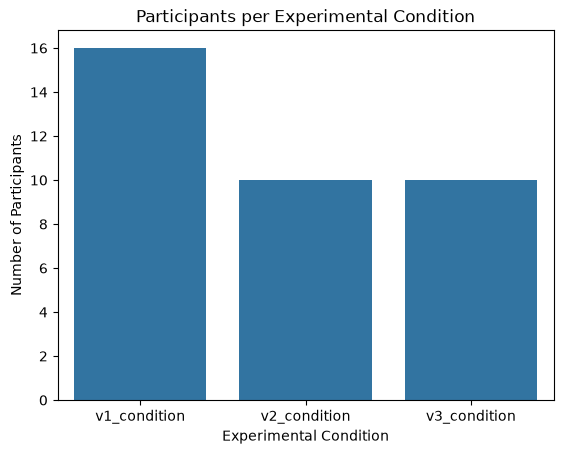

In [110]:
condition_counts = quantitative_data["condition"].value_counts().sort_index()

display(condition_counts)

sns.countplot(data=quantitative_data, x="condition", order=["v1_condition", "v2_condition", "v3_condition"])

plt.title("Participants per Experimental Condition")
plt.xlabel("Experimental Condition")
plt.ylabel("Number of Participants")
plt.show()

In [111]:
profile_columns = [
    "age_group",
    "device_type",
    "purchase_frequency",
    "computer_usage"
]

for column in profile_columns:

    print(f"\n--- {column} ---")

    display(
        pd.crosstab(
            quantitative_data["condition"],
            quantitative_data[column],
            margins=True
        )
    )


--- age_group ---


age_group,18-21,22-26,27-32,All
condition,,,,
v1_condition,3,7,5,15
v2_condition,0,8,1,9
v3_condition,1,8,1,10
All,4,23,7,34



--- device_type ---


device_type,Computer / Laptop,Smartphone,All
condition,,,
v1_condition,3,12,15
v2_condition,0,9,9
v3_condition,1,9,10
All,4,30,34



--- purchase_frequency ---


purchase_frequency,A couple of times per month,Less than once per month,Multiple times per week,All
condition,,,,
v1_condition,7,7,1,15
v2_condition,4,5,0,9
v3_condition,6,3,1,10
All,17,15,2,34



--- computer_usage ---


computer_usage,2-4 hours,5-8 hours,More than 8 hours,All
condition,,,,
v1_condition,2,6,7,15
v2_condition,4,2,3,9
v3_condition,4,3,3,10
All,10,11,13,34


# Data Analysis

## Research Question:
To what extent does cognitive workload (specifically NASA-
TLX mental demand, temporal demand, and frustration) mediate the relationship
between confirmshaming interface design and immediate promotional offer
acceptance (task compliance) in e-commerce checkout flows?